# AQI Prediction for Indian Cities: Exploratory Data Analysis

## 1. Load the data

In [1]:
import pandas as pd

df = pd.read_csv("Data/city_day.csv", parse_dates=["Date"])
print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


**Insight:** The dataset has 29,531 rows and 16 columns, with one row per city per day. The pollutant columns already show missing values (NaN) in the first rows, so cleaning will be needed.

## 2. Missing values

In [2]:
missing_pct = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing_pct)

Xylene        61.3
PM10          37.7
NH3           35.0
Toluene       27.2
Benzene       19.0
AQI           15.9
AQI_Bucket    15.9
PM2.5         15.6
NOx           14.2
O3            13.6
SO2           13.1
NO2           12.1
NO            12.1
CO             7.0
Date           0.0
City           0.0
dtype: float64


**Insight:** Xylene (61.3%), PM10 (37.7%), NH3 (35.0%) and Toluene (27.2%) have the most missing values, and AQI itself is missing in 15.9% of rows. Deleting every row with a gap would throw away most of the data, so missing values will need a careful strategy in preprocessing, and rows without a target AQI will be dropped.

### 2.1 Coverage per city

In [3]:
city_summary = df.groupby("City").agg(
    rows=("Date", "count"),
    start=("Date", "min"),
    end=("Date", "max"),
    aqi_missing_pct=("AQI", lambda s: round(s.isna().mean() * 100, 1)),
)
print(city_summary.sort_values("aqi_missing_pct", ascending=False))

                    rows      start        end  aqi_missing_pct
City                                                           
Mumbai              2009 2015-01-01 2020-07-01             61.4
Jorapokhar          1169 2017-04-20 2020-07-01             34.0
Shillong             310 2019-08-27 2020-07-01             33.9
Ahmedabad           2009 2015-01-01 2020-07-01             33.6
Talcher              925 2017-12-20 2020-07-01             24.5
Brajrajnagar         938 2017-12-07 2020-07-01             24.0
Patna               1858 2015-06-01 2020-07-01             21.5
Visakhapatnam       1462 2016-07-01 2020-07-01             19.9
Gurugram            1679 2015-11-27 2020-07-01             13.5
Amaravati            951 2017-11-24 2020-07-01             11.6
Coimbatore           386 2019-06-12 2020-07-01             10.9
Amritsar            1221 2017-02-27 2020-07-01              7.8
Kolkata              814 2018-04-10 2020-07-01              7.4
Hyderabad           2006 2015-01-04 2020

**Insight:** Mumbai has the worst AQI coverage (61.4% missing), while Delhi has the best (0.5%). Cities also differ a lot in size, from about 2,000 rows for the longest histories to only 113 for Aizawl, so thin cities may need to be dropped.

## 3. Duplicates

In [4]:
print("Duplicate City+Date:", df.duplicated(subset=["City", "Date"]).sum())

Duplicate City+Date: 0


**Insight:** There are no duplicate City and Date rows, so each city has at most one row per day. This matters because tomorrow's AQI will be created by shifting AQI back one day within each city.

## 4. Target variable: AQI

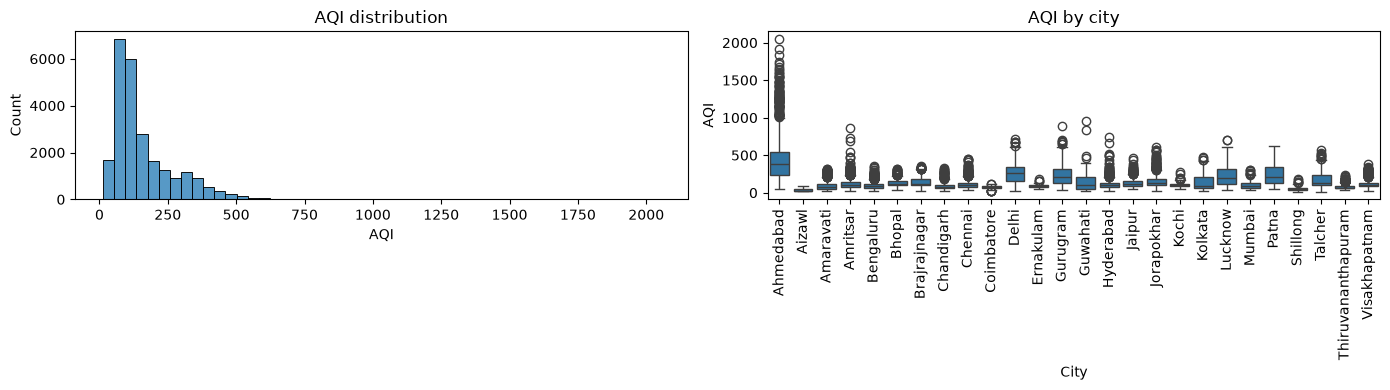

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["AQI"].dropna(), bins=50, ax=axes[0])
axes[0].set_title("AQI distribution")
sns.boxplot(data=df, x="City", y="AQI", ax=axes[1])
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("AQI by city")
plt.tight_layout()
plt.show()

**Insight:** AQI is strongly right-skewed. Most days fall between about 80 and 150, but a long tail runs past 2,000, which is far above the official 500 limit. Ahmedabad is the clear outlier among cities.

### 4.1 Extreme AQI values (above 500)

In [6]:
print("AQI > 500:", (df["AQI"] > 500).sum())
print(df[df["AQI"] > 500]["City"].value_counts())
print(df["AQI"].describe())

AQI > 500: 543
City
Ahmedabad     412
Delhi          48
Patna          25
Gurugram       22
Lucknow        15
Jorapokhar      7
Amritsar        4
Hyderabad       4
Talcher         4
Guwahati        2
Name: count, dtype: int64
count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64


**Insight:** 543 of 24,850 AQI values (about 2.2%) are above 500, and Ahmedabad holds 412 of them. The mean (166) is well above the median (118), which confirms the skew.

### 4.2 Investigating extreme AQI values in Ahmedabad

In [7]:
ahd = df[(df["City"] == "Ahmedabad") & (df["AQI"] > 500)]
print(ahd["Date"].dt.year.value_counts().sort_index())
print(ahd[["Date", "PM2.5", "PM10", "AQI"]].head(10))

Date
2015     40
2016     11
2017     31
2018    184
2019    129
2020     17
Name: count, dtype: int64
         Date   PM2.5  PM10     AQI
30 2015-01-31   94.52   NaN   514.0
31 2015-02-01  135.99   NaN   782.0
32 2015-02-02  178.33   NaN   914.0
33 2015-02-03  139.70   NaN   660.0
43 2015-02-13  103.36   NaN   510.0
44 2015-02-14  177.33   NaN   761.0
46 2015-02-16   99.70   NaN   536.0
48 2015-02-18  100.79   NaN   592.0
50 2015-02-20  140.29   NaN   588.0
51 2015-02-21  239.96   NaN  1141.0


**Insight:** Ahmedabad's extreme values appear in every year but cluster in 2018 and 2019, which hold 313 of the 412. On the rows shown, PM10 is missing and AQI is far higher than PM2.5 alone would explain, so the values look suspicious.

### 4.3 Pollutants on extreme days vs normal days (Ahmedabad)

In [8]:
cols = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3"]
ahd_city = df[df["City"] == "Ahmedabad"]
print("Extreme days (AQI > 500):")
print(ahd_city[ahd_city["AQI"] > 500][cols].mean().round(1))
print("\nNormal days (AQI <= 500):")
print(ahd_city[ahd_city["AQI"] <= 500][cols].mean().round(1))

Extreme days (AQI > 500):
PM2.5     89.9
PM10     146.3
NO2       91.5
SO2       73.2
CO        42.6
O3        43.8
NH3        NaN
dtype: float64

Normal days (AQI <= 500):
PM2.5     58.0
PM10     104.1
NO2       46.3
SO2       48.1
CO        13.0
O3        37.2
NH3        NaN
dtype: float64


**Insight:** On Ahmedabad's extreme days every pollutant is higher, but CO stands out at 42.6 against 13.0 on normal days. NH3 is missing entirely for Ahmedabad.

### 4.4 Checking whether NO and CO are duplicated in Ahmedabad

In [9]:
ahd_city = df[df["City"] == "Ahmedabad"]
other = df[df["City"] != "Ahmedabad"]

print("Ahmedabad, rows where NO equals CO:", (ahd_city["NO"] == ahd_city["CO"]).sum(), "of", len(ahd_city))
print("Other cities, rows where NO equals CO:", (other["NO"] == other["CO"]).sum(), "of", len(other))

Ahmedabad, rows where NO equals CO: 1317 of 2009
Other cities, rows where NO equals CO: 5 of 27522


**Insight:** NO equals CO in 1,317 of Ahmedabad's 2,009 rows (66%), but in only 5 of 27,522 rows elsewhere. Ahmedabad's CO column is very likely a copy of NO.

### 4.5 Overlap between extreme AQI days and copied CO rows

In [10]:
ahd_city = df[df["City"] == "Ahmedabad"].copy()
ahd_city["no_eq_co"] = ahd_city["NO"] == ahd_city["CO"]
ahd_city["extreme"] = ahd_city["AQI"] > 500
print(pd.crosstab(ahd_city["extreme"], ahd_city["no_eq_co"]))

no_eq_co  False  True 
extreme               
False       692    905
True          0    412


**Insight:** All 412 of Ahmedabad's extreme AQI days have NO equal to CO. The extreme values are therefore likely artefacts of bad CO data, not real air quality, and need careful treatment in preprocessing.

## Problem Statement

Ordinary people, such as commuters, parents, outdoor workers, students, the elderly, and anyone with asthma or heart or lung conditions, need to know tomorrow's air quality so they can decide whether to limit outdoor time, move exercise indoors, wear a mask, or keep children and elderly people inside.

This project forecasts the next day's AQI for Indian cities (regression), using today's and recent pollutant readings (PM2.5, PM10, NO2, SO2, CO, O3, NH3), the city, and date features such as month and season. The predicted AQI is then converted to an AQI category (Good to Severe) so the app can show a plain-language message.

Success is measured primarily by MAE, the average number of AQI points the forecast is off by, with RMSE and R² reported alongside it.

### Pollutants used as inputs

| Pollutant | Full name | Simple definition |
|---|---|---|
| PM2.5 | Particulate Matter below 2.5 micrometres | Very fine particles from vehicle exhaust, burning and industry. Small enough to enter the lungs and bloodstream. |
| PM10 | Particulate Matter below 10 micrometres | Coarser particles such as road and construction dust. They irritate the nose, throat and lungs. |
| NO2 | Nitrogen Dioxide | A gas from vehicles and power plants. It irritates the airways and worsens asthma. |
| SO2 | Sulphur Dioxide | A gas from burning coal and industrial fuel. It affects breathing, especially in people with asthma. |
| CO | Carbon Monoxide | A gas from incomplete burning of fuel, mostly vehicles. It reduces the oxygen carried in the blood. |
| O3 | Ground-level Ozone | Formed when sunlight reacts with other pollutants. It irritates the lungs and is worse on sunny days. |
| NH3 | Ammonia | A gas mostly from agriculture, fertilisers and waste. It irritates the eyes, nose and throat. |